In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import ListedColormap
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

import os
from prettytable import PrettyTable
from IPython.display import display

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import DBSCAN, KMeans

from sklearn.decomposition import PCA
import umap.umap_ as umap
import pacmap

base = os.getcwd().replace('\\','/')

# Preprocessing

In [2]:
def sumarryDataFromFile(data):
    mofTable                = PrettyTable()
    mofTable.field_names    = ["No","MOF", "startingTime", "endingTime", "staringRow","endingRow"]

    no                      = 1
    usefulMOF               = []
    mofCol                  = data['Modo de Falla']
    preMOF                  = None
    beginingRow             = 0
    beginingTime            = 0


    for idx in range(len(data)):
        curIdx = idx
        preIdx = idx -1

        if (mofCol[curIdx] != preMOF) and curIdx!=0:
            # --------------------------
            # Collect the last state
            # --------------------------
            endingTime      = data['tiempo'][preIdx] 
            endingRow       = preIdx
            
            if not pd.isna(preMOF):
                mofTable.add_row([no,preMOF, beginingTime,endingTime,beginingRow+2,endingRow+2])
                no +=1
                
                if preMOF not in usefulMOF:
                    usefulMOF.append(preMOF)
            
            # --------------------------
            # Assign new state
            # --------------------------
            preMOF          = mofCol[curIdx]
            beginingTime    = data['tiempo'][curIdx]
            beginingRow     = curIdx
            
    
    print("All the mode of failure:",usefulMOF)
    print(mofTable)

In [3]:
input_variables = ['corriente(A)', 'velocidad(rpm)', 'Potencia(kW)', 'posicion_poste(%)', 'presion_estanque_aire(bar)', 'Eje_piñón_aceite(%)',
                   'Lubricación_principal(psi)', 'Lubricación_principal(A)', 'Lubricación_respaldo(psi)', 'Lubricación_respaldo(A)',
                   'Lubricación_post_filtros(psi)', 'Lubricación_válvula_MPS(psi)',  'Lubricación_entrada_sup(psi)',
                    'Lubricación_entrada_inf(psi)', 'Lubricación_entrada_sup(m3/h)', 'Lubricación_entrada_inf(m3/h)', 'Lubricación_depósito(%)',
                    'Motor_Fase1(A)', 'Motor_Fase2(A)', 'Motor_Fase3(A)', 'Motor_Fase1(V)', 'Motor_Fase2(V)', 'Motor_Fase3(V)']

usedCriticalMOF = [ "Válvula defectuosa",
                    "Mantención programada", 
                    "Falta de aceite hidráulico",
                    "Lubricación  deficiente",
                    "Temperatura fuera de rango",
                    "Bomba hidráulica con fuga",
                    "Fuga de aceite",
                    "Falla en sistema hidráulico",
                    "Falla sistema de hidroset-poste",
                    "Mandibulas o revestimiento suelto"
                                   ]

In [4]:
notModeOfFailure  = [  "Stand by",
                                    "Stock de producto lleno",
                                    "Cambio de Turno",
                                    "Tronadura",
                                    "Falla o problemas aguas arriba",
                                    "Falta de equipo carguío mina",
                                    "Otra falla mecánica",
                                    "Limpieza equipo",
                                    "Detención por Enclavamiento",
                                    "Colación",
                                    "Falla o problemas aguas abajo",
                                    "Ajuste de Setting (Asociado al Plan)",
                                    "Falta de inventario",
                                    "Otra falla instrumentación",
                                    "Falta de Equipos de Apoyo",
                                    "Puesta en Marcha o sistema en vació",
                                    "Bloqueo de Equipos",
                                    "Factor Climático",
                                    "Inspección de equipo ante evento operacional (chatarra, falsa alarma etc)",
                                    "Puesta en marcha de equipos o sistemas en vacío",
                                    "Sensor nivel lectura errónea",
                                    "Corte energía interno",
                                    "Esperas de personal de reparación y/o repuestos y/o equipos de apoyo y/o movimiento de traslado (ins)",
                                    "Esperas de personal de reparación y/o repuestos y/o equipos de apoyo y/o movimiento de traslado (mec)",
                                    "Factor Externo (huelgas, manifestaciones, cortes de caminos, etc)",
                                    "Otra falla operacional",
                                    "Sensor de flujo lectura errónea",
                                    "Sobrecarga, Rebalses y atollos"
                                    ]

In [5]:
df_crusher_1_raw = pd.read_hdf('data\criticalMOFCrusher1.h5')

In [6]:
df_crusher_1 = df_crusher_1_raw.copy()

In [7]:
df_crusher_1.loc[df_crusher_1['Modo de Falla'].isin(usedCriticalMOF), 'event'] = df_crusher_1[df_crusher_1['Modo de Falla'].isin(usedCriticalMOF)].groupby(['Inicio Reportado', 'Fin Reportado']).ngroup().astype('str')

In [8]:
df_first = df_crusher_1[df_crusher_1['Modo de Falla'].isin(['Mantención programada']+usedCriticalMOF)].drop_duplicates(keep='first', subset=['Modo de Falla', 'Inicio Reportado', 'Fin Reportado'])
df_last = df_crusher_1[df_crusher_1['Modo de Falla'].isin(['Mantención programada']+usedCriticalMOF)].drop_duplicates(keep='last', subset=['Modo de Falla', 'Inicio Reportado', 'Fin Reportado'])
df_MOF = pd.concat([df_first, df_last]).sort_values(by='tiempo')
del df_first, df_last
df_MOF[['Modo de Falla', 'Inicio Reportado', 'Fin Reportado']]

,Modo de Falla,Inicio Reportado,Fin Reportado
4774,Válvula defectuosa,2023-01-06 10:51:43,2023-01-06 15:13:56
5035,Válvula defectuosa,2023-01-06 10:51:43,2023-01-06 15:13:56
16996,Mantención programada,2023-01-19 00:54:00,2023-01-19 01:53:09
17055,Mantención programada,2023-01-19 00:54:00,2023-01-19 01:53:09
17146,Mantención programada,2023-01-19 03:23:58,2023-01-19 23:12:31
...,...,...,...
294999,Bomba hidráulica con fuga,2023-12-03 08:00:00,2023-12-03 15:17:42
309116,Mantención programada,2023-12-19 03:55:45,2023-12-19 04:18:32
309138,Mantención programada,2023-12-19 03:55:45,2023-12-19 04:18:32
309179,Mantención programada,2023-12-19 04:58:54,2023-12-20 10:39:01


In [9]:
mask = df_crusher_1['event'].isnull()
groups = mask.ne(mask.shift()).cumsum().astype('str')
df_crusher_1['trajectory'] = np.where(mask, groups, np.nan)

## Plot period of time series between events

In [24]:
variable = input_variables[2] #df_crusher_1.select_dtypes('number').columns[3]
fig = px.line(df_crusher_1, x='tiempo', y=variable, color='trajectory')
fig.show()

# Preprocessing 2

In [11]:
count=df_crusher_1.groupby('trajectory').size().reset_index(name='count')
df_crusher_1 = pd.merge(df_crusher_1, count, on='trajectory')
df_crusher_1=df_crusher_1[df_crusher_1['count']>1000]
df_crusher_1['count']=df_crusher_1['count'].astype('str')

In [12]:
# Standardize the data
scaler = MinMaxScaler() 
scaled_data = scaler.fit_transform(df_crusher_1.select_dtypes('number'))
df_scaled = df_crusher_1.copy()
df_scaled.loc[:, df_crusher_1.select_dtypes('number').columns] = scaled_data
df_input = df_scaled[input_variables]

# Dimensionality reduction and clustering

In [13]:
#Train clustering model

#pca_model = PCA(n_components=2)
umap_model = umap.UMAP(n_components=2)
pacmap_model = pacmap.PaCMAP(n_components=2, save_tree=True) 

trajectory='15'
df_input_trajectory = df_input[df_crusher_1['trajectory']==trajectory]
#pca_model.fit(df_input_trajectory)
umap_model.fit(df_input_trajectory)
pacmap_model.fit(df_input_trajectory)

PaCMAP(pair_FP=array([[    0, 16123],
       [    0, 15084],
       [    0,  4847],
       ...,
       [21870,  3619],
       [21870, 18579],
       [21870, 19149]]),
       pair_MN=array([[    0, 19443],
       [    0, 16564],
       [    0, 14959],
       ...,
       [21870, 16916],
       [21870, 10369],
       [21870, 18414]]),
       pair_neighbors=array([[    0, 21682],
       [    0,  5314],
       [    0, 18652],
       ...,
       [21870, 21860],
       [21870, 21863],
       [21870, 21838]]),
       random_state=0, save_tree=True)

In [14]:
# clusters = {}

# for trajectory in df_crusher_1.trajectory.dropna().unique():
#     df_input_trajectory = df_input[df_crusher_1['trajectory']==trajectory]

#     transformed_data_pacmap = pacmap_model.transform(df_input_trajectory)

#     dbscan_model = DBSCAN(eps=3, min_samples=60, n_jobs=-1)
#     clusters_dbscan_pacmap = dbscan_model.fit_predict(transformed_data_pacmap)

#     df_input_experiment = df_input_trajectory.copy()
#     df_input_experiment['tiempo'] = df_crusher_1[df_crusher_1['trajectory']==trajectory]['tiempo']
    
#     df_input_experiment['pacmap_x'] = transformed_data_pacmap[:, 0]
#     df_input_experiment['pacmap_y'] = transformed_data_pacmap[:, 1]
#     df_input_experiment['pacmap_z'] = transformed_data_pacmap[:, 2]

#     df_input_experiment['dbscan_pacmap'] = clusters_dbscan_pacmap.astype('str')

#     clusters[trajectory]= df_input_experiment

In [15]:
clusters = {}

for trajectory in df_crusher_1.trajectory.dropna().unique():
    df_input_trajectory = df_input[df_crusher_1['trajectory']==trajectory]

    # pca_model = PCA(n_components=3)
    # umap_model = umap.UMAP(n_components=3)
    # pacmap_model = pacmap.PaCMAP(n_components=3) 

    #transformed_data_pca = pca_model.transform(df_input_trajectory)
    transformed_data_umap = umap_model.transform(df_input_trajectory)
    transformed_data_pacmap = pacmap_model.transform(df_input_trajectory)

    #dbscan_model = DBSCAN(eps=0.9, min_samples=60, n_jobs=-1)
    #clusters_dbscan_pca = dbscan_model.fit_predict(transformed_data_pca)

    dbscan_model = DBSCAN(eps=2.4, min_samples=60, n_jobs=-1)
    clusters_dbscan_umap = dbscan_model.fit_predict(transformed_data_umap)

    dbscan_model = DBSCAN(eps=2.4, min_samples=60, n_jobs=-1)
    clusters_dbscan_pacmap = dbscan_model.fit_predict(transformed_data_pacmap)

    df_input_experiment = df_input_trajectory.copy()
    df_input_experiment['tiempo'] = df_crusher_1[df_crusher_1['trajectory']==trajectory]['tiempo']

    #df_input_experiment['pca_x'] = transformed_data_pca[:, 0]
    #df_input_experiment['pca_y'] = transformed_data_pca[:, 1]
    #df_input_experiment['pca_z'] = transformed_data_pca[:, 2]

    df_input_experiment['umap_x'] = transformed_data_umap[:, 0]
    df_input_experiment['umap_y'] = transformed_data_umap[:, 1]
    #df_input_experiment['umap_z'] = transformed_data_umap[:, 2]
    
    df_input_experiment['pacmap_x'] = transformed_data_pacmap[:, 0]
    df_input_experiment['pacmap_y'] = transformed_data_pacmap[:, 1]
    #df_input_experiment['pacmap_z'] = transformed_data_pacmap[:, 2]

    #df_input_experiment['dbscan_pca'] = clusters_dbscan_pca.astype('str')
    df_input_experiment['dbscan_umap'] = clusters_dbscan_umap.astype('str')
    df_input_experiment['dbscan_pacmap'] = clusters_dbscan_pacmap.astype('str')

    clusters[trajectory]= df_input_experiment
    

In [16]:
stop

NameError: name 'stop' is not defined

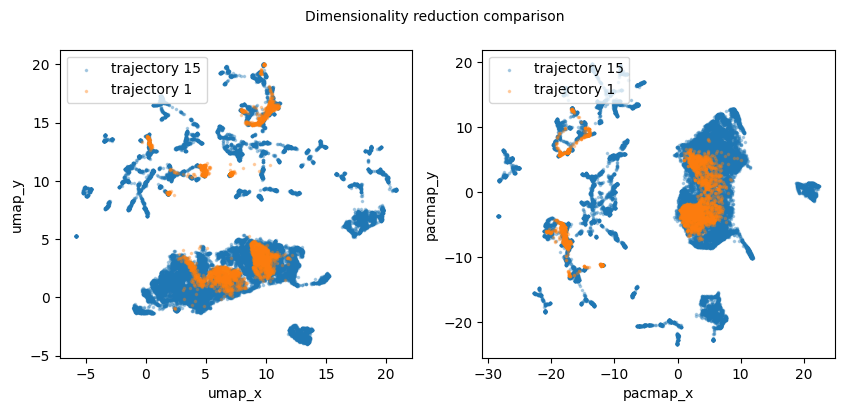

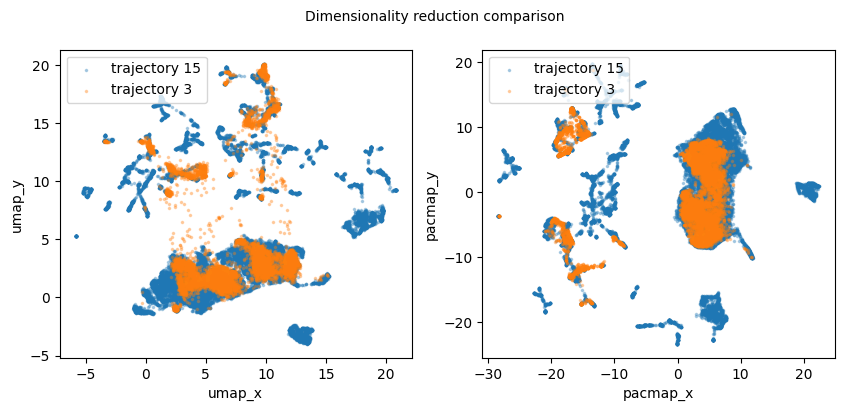

In [43]:
cmap = ListedColormap(sns.color_palette("hls", 256).as_hex())
clustering_algorithms= ['umap', 'pacmap']
trajectories = df_crusher_1.trajectory.unique()

trajectory1 = '15'
n_rows, n_cols = 2,2 #len(df_crusher_1.trajectory.unique()), 3

for i in range(n_rows):
    trajectory = trajectories[i]
    fig, axes = plt.subplots(1, n_cols, figsize=(10, 4))
    for j in range(n_cols):
        algorithm = clustering_algorithms[j]

        #scatterplot = 
        axes[j].scatter(x=clusters[trajectory1][f'{algorithm}_x'], 
                                        y=clusters[trajectory1][f'{algorithm}_y'], 
                                        label = f'trajectory {trajectory1}',
                                        s=10, marker='.', alpha=0.3)
        
        axes[j].scatter(x=clusters[trajectory][f'{algorithm}_x'], 
                                        y=clusters[trajectory][f'{algorithm}_y'], 
                                        label = f'trajectory {trajectory}',
                                        s=10, marker='.', alpha=0.3)
        
        axes[j].set_xlabel(f'{algorithm}_x')
        axes[j].set_ylabel(f'{algorithm}_y')
        axes[j].legend(loc='upper left')
        #axes.legend(*scatterplot.legend_elements(), loc='upper left')
    fig.suptitle(f'Dimensionality reduction comparison', fontsize=10) #, y=0.88)

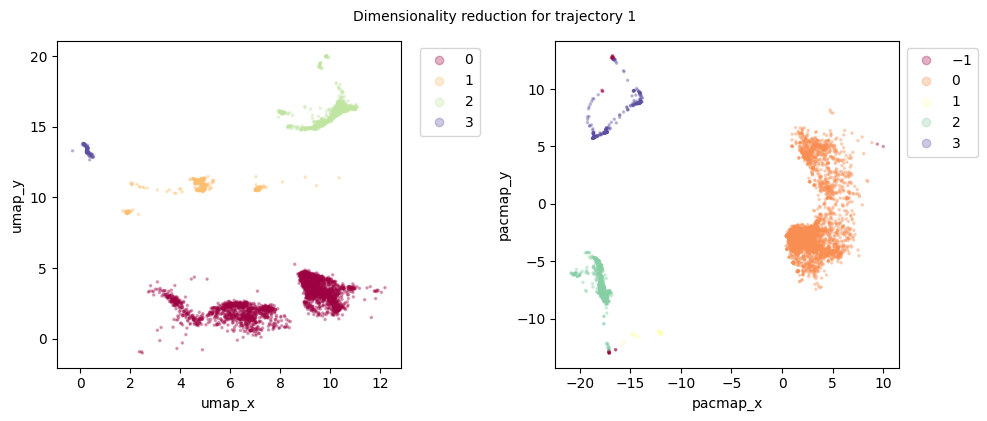

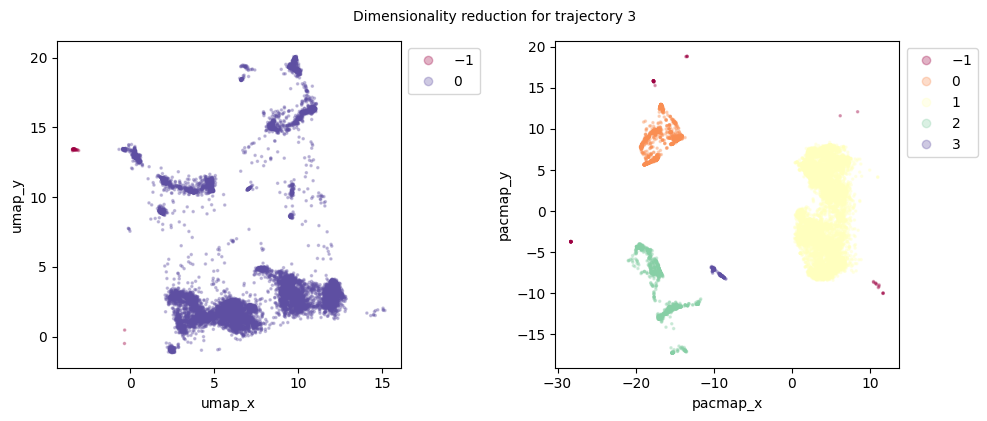

In [42]:
cmap = ListedColormap(sns.color_palette("Spectral", 256).as_hex())
clustering_algorithms= ['umap', 'pacmap']
trajectories = df_crusher_1.trajectory.unique()

n_rows, n_cols = 2,2 #len(df_crusher_1.trajectory.unique()), 3
for i in range(n_rows):
    fig, axes = plt.subplots(1, n_cols, figsize=(10, 4))
    trajectory = trajectories[i]
    for j in range(n_cols):
        algorithm = clustering_algorithms[j]

        scatterplot = axes[j].scatter(x=clusters[trajectory][f'{algorithm}_x'], 
                                      y=clusters[trajectory][f'{algorithm}_y'], 
                                      #zs=clusters[trajectory][f'{algorithm}_z'], 
                                      c=clusters[trajectory][f'dbscan_{algorithm}'].astype('int'),   
                                      s=10, marker='.', cmap=cmap, alpha=0.3)
        
        axes[j].set_xlabel(f'{algorithm}_x')
        axes[j].set_ylabel(f'{algorithm}_y')
        #axes[j].set_zlabel(f'{algorithm}_z')
        axes[j].legend(*scatterplot.legend_elements(), loc='upper right', bbox_to_anchor=(1.25, 1))
    fig.tight_layout()
    fig.suptitle(f'Dimensionality reduction for trajectory {trajectory}', fontsize=10, y=1.04)

In [183]:
d[d.dbscan_pacmap.isin(cluster_labels)][variable].min()

0.5079974259701634

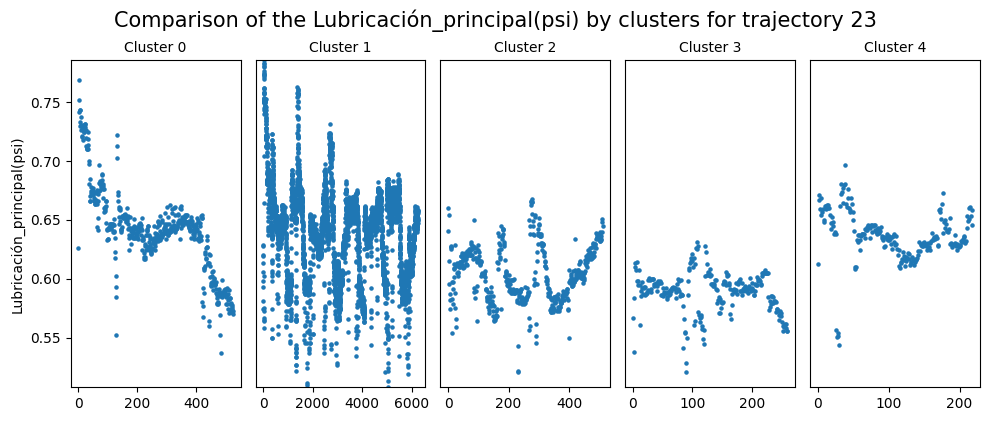

In [189]:
trajectory='23'
d=clusters[trajectory]
cluster_labels=d.dbscan_pacmap.unique()[d.dbscan_pacmap.unique()!=str(-1)]
variable=d.select_dtypes('number').columns[6]

ymax = d[d.dbscan_pacmap.isin(cluster_labels)][variable].max()
ymin = d[d.dbscan_pacmap.isin(cluster_labels)][variable].min()

fig, axes = plt.subplots(1, len(cluster_labels), figsize=(10, 4))

for j,c in enumerate(cluster_labels):
    if int(c)==-1:
        continue

    dc=d[d['dbscan_pacmap']==c]
    axes[j].scatter(x=dc.reset_index().index, y=dc[variable], s=5)
    axes[j].set_title(f'Cluster {c}', fontsize=10)
    axes[j].set_ylim(ymin, ymax)

    if j==0:
        axes[j].set_ylabel(f'{variable}')
    else:
        axes[j].yaxis.set_visible(False)
fig.tight_layout()
fig.suptitle(f'Comparison of the {variable} by clusters for trajectory {trajectory}', fontsize=15, y=1.04)
plt.show()

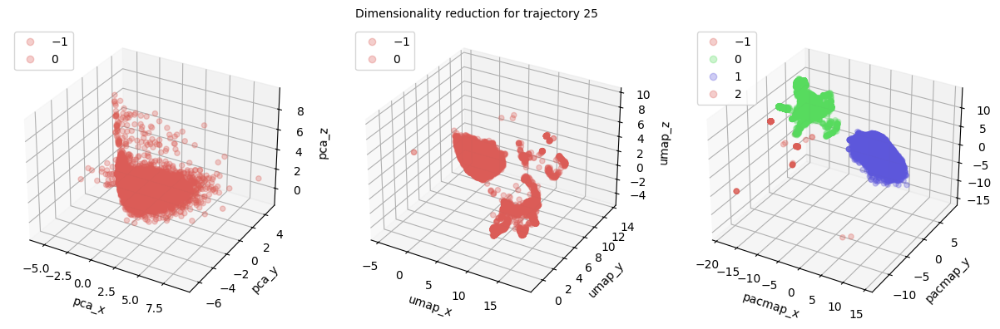

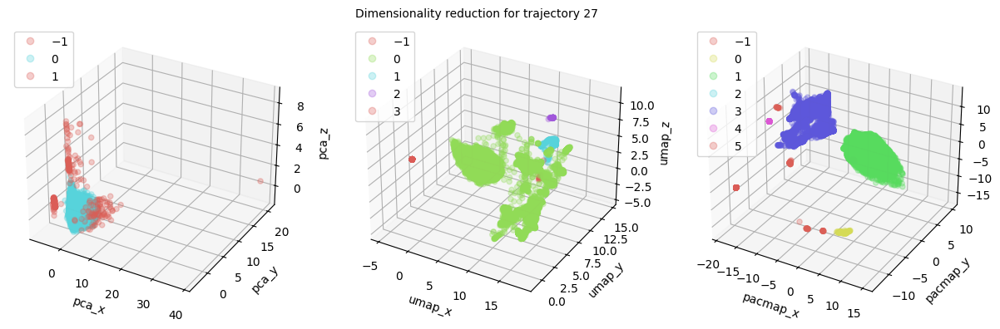

In [ ]:
cmap = ListedColormap(sns.color_palette("hls", 256).as_hex())
clustering_algorithms= ['pca', 'umap', 'pacmap']
trajectories = df_crusher_1.trajectory.unique()

n_rows, n_cols = 2,3 #len(df_crusher_1.trajectory.unique()), 3
for i in range(n_rows):
    fig, axes = plt.subplots(1, n_cols, figsize=(15, 5), subplot_kw={"projection": "3d"})
    trajectory = trajectories[i+10]
    for j in range(n_cols):
        algorithm = clustering_algorithms[j]

        scatterplot = axes[j].scatter(xs=clusters[trajectory][f'{algorithm}_x'], 
                                      ys=clusters[trajectory][f'{algorithm}_y'], 
                                      zs=clusters[trajectory][f'{algorithm}_z'], 
                                      c=clusters[trajectory][f'dbscan_{algorithm}'].astype('int'),   
                                      s=20, marker='o', cmap=cmap, alpha=0.3)
        
        axes[j].set_xlabel(f'{algorithm}_x')
        axes[j].set_ylabel(f'{algorithm}_y')
        axes[j].set_zlabel(f'{algorithm}_z')
        axes[j].legend(*scatterplot.legend_elements(), loc='upper left')
    fig.suptitle(f'Dimensionality reduction for trajectory {trajectory}', fontsize=10, y=0.88)
        
    # plt.savefig(f'clustering_figures\{trajectory}.png')
    # plt.close(fig)


In [ ]:
import tqdm

In [ ]:
trajectory=df_crusher_1.trajectory.unique()[2]
variable=clusters[trajectory].columns[2] #'corriente(A)'
algorithm='pacmap'

fig = px.scatter(clusters[trajectory], x='tiempo', y=variable, color=f'dbscan_{algorithm}')
line_plot = px.line(clusters[trajectory], x='tiempo', y=variable)

fig.add_trace(line_plot.data[0])
fig.update_traces(line=dict(color='black'))
fig.show()

In [ ]:
# algorithm = 'pacmap'
# fig = px.scatter_3d(df_input_experiment, x=f'{algorithm}_x', y=f'{algorithm}_y', 
#                     z=f'{algorithm}_z',
#                     color=f'dbscan_{algorithm}', size_max = 10)
# fig.update_layout(width=600,height=500)
# fig.show()

# Cluster Comparison

In [114]:
from sklearn.metrics.pairwise import euclidean_distances

In [122]:
def getTrajectory(idx):
    trajectory  = trajectories[idx]
    trajectoryResult = clusters[trajectory]

    return trajectory, trajectoryResult


# =====================================
# This func calculates the average 
# of each cluster in the embedded space
# -------------------------------------
def getCentroids( data, algorithm):
    embeddingData   = data[[f'{algorithm}_x', f'{algorithm}_y']] #, f'{algorithm}_z']]
    clusterLabels   = data[f'dbscan_{algorithm}'].astype('int')

    centroids = []
    for label in clusterLabels.unique():
        if label == -1: # Outliers are ignored
            continue

        cluster_points = embeddingData[clusterLabels == label]
        centroid       = np.mean(cluster_points, axis=0).values
        centroids.append(centroid)

    return embeddingData, clusterLabels, np.array(centroids)

In [124]:
L               = len(clusters)
iterator        = 0 
threshold =5
similarClusters = pd.DataFrame()
for idxTrajectory1 in range(L):
    for idxTrajectory2 in range(idxTrajectory1+1, L):

        # =========================
        # Calculates centroids     
        # for pairs of trajectories
        # -------------------------
        trajectory1, dataTrajectory1                = getTrajectory(idxTrajectory1) 
        embeddingData1, clusterLabels1, centroids1  = getCentroids(dataTrajectory1, algorithm)

        trajectory2, dataTrajectory2                = getTrajectory(idxTrajectory2)
        embeddingData2, clusterLabels2, centroids2  = getCentroids(dataTrajectory2, algorithm)

        # ==========================
        # centroids whose distance 
        # is less than the threshold 
        # are considered similar
        # --------------------------
        distances                                   = euclidean_distances(centroids1, centroids2)
        for i, row in enumerate(distances):
            for j, distance in enumerate(row):
                if distance < threshold:
                    cluster1, cluster2              = (i,j) 
                    pointsCluster1                  = embeddingData1[clusterLabels1 == cluster1].copy()
                    pointsCluster2                  = embeddingData2[clusterLabels2 == cluster2].copy() 
                    pointsCluster1.loc[:,'label']   = f'cluster: {cluster1}, trajectory:{trajectory1}'
                    pointsCluster2.loc[:,'label']   = f'cluster: {cluster2}, trajectory:{trajectory2}'
                    
                    dfResuts                        = pd.concat([pointsCluster1, pointsCluster2])
                    dfResuts.loc[:, 'group']        = iterator
                    similarClusters            = pd.concat([similarClusters, dfResuts], ignore_index=True)
                    iterator+=1

In [125]:
from utils.plotFigures      import lineAndScatterPlot, scatterPlot2D, scatterPlot3D

In [136]:
similarClusters['group'].unique()

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [168]:
idxGroupCluster = 100
scatterPlot2D(data  = similarClusters[similarClusters['group']==idxGroupCluster], 
              x     = 'pacmap_x', 
              y     = 'pacmap_y', 
              #z     = 'pacmap_z', 
              color = 'label')

## -----------------

In [ ]:
def calculateCentroids(data, trajectory, algorithm):
    df_trajectory_reduced = data[trajectory][[f'{algorithm}_x',f'{algorithm}_y', f'{algorithm}_z']]
    labels_trajectory = data[trajectory][f'dbscan_{algorithm}']

In [ ]:
trajectories = df_crusher_1.trajectory.unique()
trajectories

algorithm='pacmap'
for trajectory1 in trajectories:
    for trajectory2 in trajectories:
        if trajectory1==trajectory2:
            continue


In [ ]:
trajectories = df_crusher_1.trajectory.unique()
i=2
trajectory = trajectories[0]
trajectory2 = trajectories[0+i]
algorithm='pacmap'

In [ ]:
df_trajectory_reduced = clusters[trajectory][[f'{algorithm}_x',f'{algorithm}_y', f'{algorithm}_z']]
labels_trayectory = clusters[trajectory][f'dbscan_{algorithm}']

df_trajectory2_reduced = clusters[trajectory2][[f'{algorithm}_x',f'{algorithm}_y', f'{algorithm}_z']]
labels_trayectory2 = clusters[trajectory2][f'dbscan_{algorithm}']

In [ ]:
representatives1 = []
for label in np.unique(labels_trayectory):
    if int(label)==-1:
        continue

    cluster_points = df_trajectory_reduced[labels_trayectory == label]
    representative = np.mean(cluster_points, axis=0).values
    representatives1.append(representative)


representatives2 = []
for label in np.unique(labels_trayectory2):
    if int(label)==-1:
        continue

    cluster_points = df_trajectory2_reduced[labels_trayectory2 == label]
    representative = np.mean(cluster_points, axis=0).values
    representatives2.append(representative)

representatives1, representatives2 = np.array(representatives1), np.array(representatives2)

In [ ]:
distances = euclidean_distances(representatives1, representatives2)

threshold = 5
similar_clusters = []
for i, row in enumerate(distances):
    for j, distance in enumerate(row):
        if distance < threshold:
            similar_clusters.append((i, j))
            
for cluster_pair in similar_clusters:
    cluster1_index, cluster2_index = cluster_pair
    cluster1_points = df_trajectory_reduced[labels_trayectory == str(cluster1_index)]
    cluster2_points = df_trajectory2_reduced[labels_trayectory2 == str(cluster2_index)]

if len(similar_clusters)!=0:
    cluster1_points.loc[:,'label']=f'cluster: {cluster1_index}, trajectory:{trajectory}'
    cluster2_points.loc[:,'label']=f'cluster: {cluster2_index}, trajectory:{trajectory2}'


In [ ]:
fig = px.scatter_3d(pd.concat([cluster1_points, cluster2_points]), 
                    x=f'{algorithm}_x', 
                    y=f'{algorithm}_y', 
                    z=f'{algorithm}_z',
                    color='label', size_max = 10)
fig.update_layout(width=600,height=500)
fig.show()

In [ ]:
df1 = clusters[trajectory][clusters[trajectory][f'dbscan_{algorithm}']==str(cluster1_index)]
df1['label'] = f'cluster: {cluster1_index}, trajectory:{trajectory}'

df2 = clusters[trajectory2][clusters[trajectory2][f'dbscan_{algorithm}']==str(cluster2_index)]
df2['label'] = f'cluster: {cluster2_index}, trajectory:{trajectory2}'

In [ ]:
trajectory=df_crusher_1.trajectory.unique()[15]
variable=clusters[trajectory].columns[3] #'corriente(A)'
algorithm='pacmap'
df=pd.concat([df1,df2])
fig = px.scatter(df, x='tiempo', y=variable, color='label')
line_plot = px.line(df, x='tiempo', y=variable)

fig.add_trace(line_plot.data[0])
fig.update_traces(line=dict(color='black'))
fig.show()

In [ ]:
clusters[trajectory]['dbscan_pacmap'].apply(lambda row: chr(ord('A') + int(row))).replace('@', 'Z')[::10]

# GPT-2

In [ ]:
import torch
from transformers import GPT2Tokenizer, GPT2LMHeadModel

In [ ]:
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2")

In [ ]:
# GPT-2
def predict_next_words(sequence, model, tokenizer, num_words):
    # tokenization
    input_ids = tokenizer.encode(sequence, return_tensors='pt')

    # generate next words
    with torch.no_grad():
        output = model.generate(
            input_ids=input_ids,
            max_length=len(input_ids[0]) + num_words, 
            pad_token_id=model.config.eos_token_id,
            #num_return_sequences=1,
            do_sample=True,
            top_k=50,
            top_p=0.95,
        )
    
    # decode words
    next_words = tokenizer.decode(output[0, len(input_ids[0]):], skip_special_tokens=True)
    
    return next_words

In [ ]:
sequence = ' '.join(clusters[trajectory]['dbscan_pacmap'].apply(lambda row: chr(ord('A') + int(row))).replace('@', 'Z')[::10]) #'A A A B B A C A A C C B B A A C B A' #"the weather is"
num_words = 10  # number of words to predict

next_words = predict_next_words(sequence, model, tokenizer, num_words)
print(next_words)
print(sequence+next_words)